In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

from datasets import load_dataset

dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()


df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notnull(x) else x)

c:\Users\dee\anaconda3\envs\data_analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#df = df.explode("job_skills")

In [4]:
df['job_title_short'].unique()

<ArrowStringArray>
[     'Senior Data Engineer',              'Data Analyst',
             'Data Engineer',          'Business Analyst',
            'Data Scientist', 'Machine Learning Engineer',
       'Senior Data Analyst',            'Cloud Engineer',
     'Senior Data Scientist',         'Software Engineer']
Length: 10, dtype: str

In [5]:
selected_jobs = [
    'Data Scientist',
    'Data Analyst',
    'Data Engineer'
]

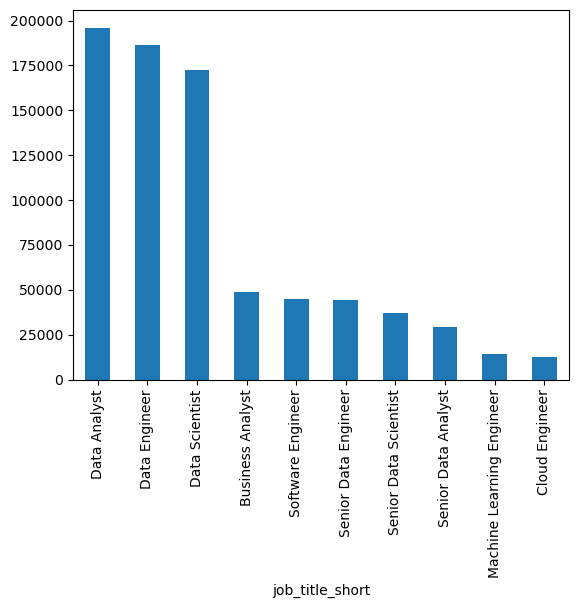

In [6]:
# create a simple subplot
fig, ax = plt.subplots()

# plot the data
df['job_title_short'].value_counts().plot(kind='bar', ax=ax)
plt.show()

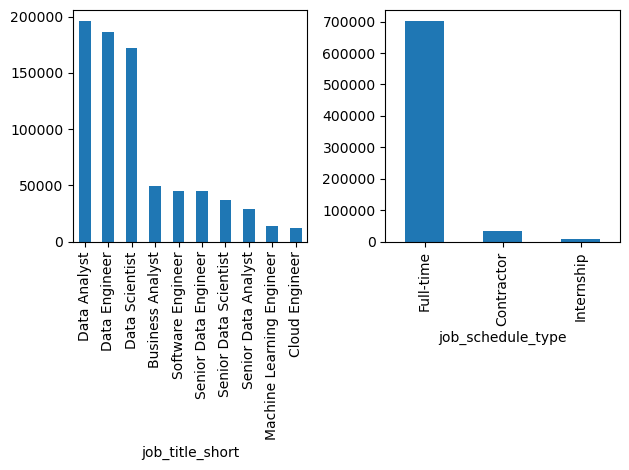

In [7]:
fig, ax = plt.subplots(1, 2)

df['job_title_short'].value_counts().plot(kind='bar', ax=ax[0])
df['job_schedule_type'].value_counts().head(3).plot(kind='bar', ax=ax[1])

# fix the overlap
fig.tight_layout()

plt.show()

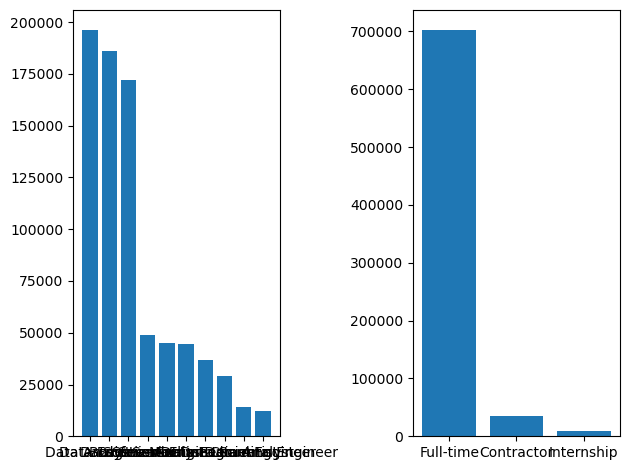

In [8]:
fig, ax = plt.subplots(1, 2)

ax[0].bar(df['job_title_short'].value_counts().index, df['job_title_short'].value_counts())
ax[1].bar(df['job_schedule_type'].value_counts().head(3).index, df['job_schedule_type'].value_counts().head(3))

fig.tight_layout()

plt.show()

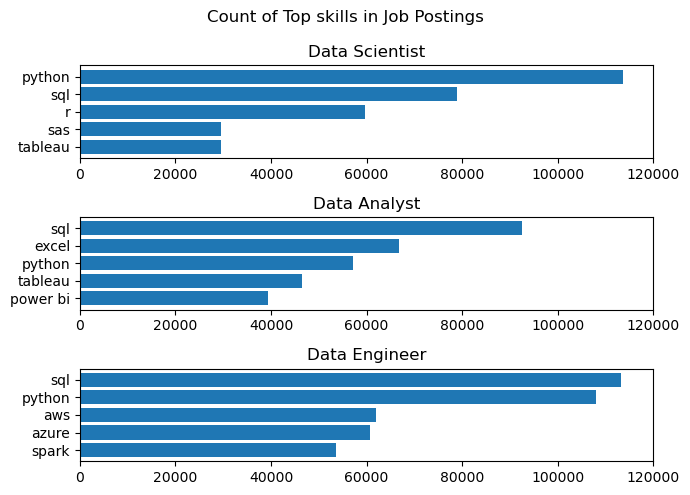

In [3]:
import matplotlib.pyplot as plt

selected_jobs = [
    'Data Scientist',
    'Data Analyst',
    'Data Engineer'
]

fig, ax = plt.subplots(
    nrows=len(selected_jobs),
    figsize=(7, 5)
)

for i, job in enumerate(selected_jobs):

    job_df = df.loc[
        df['job_title_short'].eq(job),
        ['job_skills']
    ].dropna(subset=['job_skills'])
    job_skills = job_df['job_skills'].value_counts().head(5)
                                                        

    job_skills = job_df.explode('job_skills')['job_skills'].value_counts().head(5)
    ax[i].barh(job_skills.index, job_skills.values)
    ax[i].set_title(f'{job}')
    ax[i].set_xlabel('')
    ax[i].set_ylabel('')
    ax[i].set_xlim(0, 120000)
    ax[i].invert_yaxis()  # Invert y-axis to have the highest count on top

fig.suptitle('Count of Top skills in Job Postings')
fig.tight_layout()

plt.show()